# TP Jour 2 — Modèle d'Exécution Spark, Jointures Multi-Datasets & Couche Silver (Delta Lake)

### Objectifs de la séance
1. Observer la **Lazy Evaluation** et distinguer transformations **Narrow** vs **Wide (Shuffle)** sur **Spark Web UI** (`http://localhost:4040`).
2. Profiler la qualité de vos tables **Bronze** (issues d'un ou **plusieurs datasets Kaggle**), nettoyer les anomalies, typer fortement les colonnes et harmoniser les **clés de jointure inter-sources**.
3. Mettre en œuvre une **jointure distribuée multi-datasets maîtrisée** (`BroadcastHashJoin` via `F.broadcast` pour un référentiel/dataset compact, ou `SortMergeJoin` entre deux grandes sources) **en contrôlant la cardinalité (absence d'explosion N-à-M)**.
4. Sauvegarder votre table analytique enrichie dans **`/lakehouse/silver/`** et expérimenter les garanties **ACID de Delta Lake** (`_delta_log`, **Schema Enforcement**, **`MERGE INTO`**, **Time Travel**).

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from delta.tables import DeltaTable

spark = (
    SparkSession.builder
    .appName("J2_Spark_Delta_Silver")
    .getOrCreate()
)

print("Session Spark active — Spark UI : http://localhost:4040")

Session Spark active — Spark UI : http://localhost:4040


## 1. Chargement de vos tables Bronze (Multi-Datasets / Multi-Tables) & Diagnostic Qualité

### Exercice 1.1 — Charger toutes vos tables Bronze et profiler valeurs manquantes / doublons
1. Chargez dans `bronze_dfs` votre table de faits principale ainsi que la (ou les) table(s) secondaire(s) à joindre depuis `/lakehouse/bronze/<nom_table>`.
2. Comptez le nombre de valeurs `NULL` sur vos colonnes clés (en particulier les **clés de jointure**) ainsi que les doublons éventuels.

In [2]:
# TODO : Déclarer vos tables Bronze à croiser (table principale + dataset(s) / table(s) secondaire(s))
BRONZE_TABLES: dict[str, str] = {
    "main": "/lakehouse/bronze/cab_rides",    # faits : 1 ligne = 1 course Uber ou Lyft
    "secondary": "/lakehouse/bronze/weather", # jointure : relevés météo par quartier
}

assert len(BRONZE_TABLES) > 0, "TODO : Renseignez vos chemins Delta Bronze dans `BRONZE_TABLES`."
bronze_dfs = {alias: spark.read.format("delta").load(path) for alias, path in BRONZE_TABLES.items()}
for alias, df in bronze_dfs.items():
    print(f"[{alias}] {BRONZE_TABLES[alias]} -> {df.count():,} lignes | colonnes : {df.columns[:8]}")

# TODO : Pointer `df_bronze` sur votre table principale et calculer le diagnostic de valeurs nulles `null_report`
df_bronze = bronze_dfs.get("main")

# Valeurs manquantes réelles (NULL) + chaînes « sentinelles » qui masquent un vide ("", "NA", "null"...)
SENTINELLES = ["", "na", "n/a", "null", "none", "nan", "?", "unknown"]
lignes_rapport = []
for alias, df in bronze_dfs.items():
    total = df.count()
    exprs = []
    for col_name, dtype in df.dtypes:
        if col_name.startswith("_"):
            continue
        cond = F.col(col_name).isNull()
        if dtype == "string":
            cond = cond | F.lower(F.trim(F.col(col_name))).isin(SENTINELLES)
        exprs.append(F.count(F.when(cond, 1)).alias(col_name))
    for col_name, n in df.select(exprs).first().asDict().items():
        lignes_rapport.append((alias, col_name, dict(df.dtypes)[col_name], int(n), round(100.0 * n / total, 2)))
null_report = spark.createDataFrame(lignes_rapport, ["table", "colonne", "type", "nb_manquants", "pct_manquant"])
assert null_report is not None, "TODO : Calculez le diagnostic de valeurs nulles `null_report`."
null_report.show(truncate=False)

# Qui sont les courses sans prix ? (mécanisme du vide)
df_bronze.filter(F.col("price").isNull()).groupBy("cab_type", "name").count().show()

# Doublons sur les identifiants / clés
n_rides, n_ids = df_bronze.count(), df_bronze.select("id").distinct().count()
print(f"cab_rides : {n_rides:,} lignes | {n_ids:,} id distincts | doublons sur `id` : {n_rides - n_ids:,}")
w = bronze_dfs["secondary"]
print(f"weather   : doublons sur (location, time_stamp) : {w.count() - w.select('location', 'time_stamp').distinct().count():,}")

# Risque d'explosion N-M : combien de relevés météo pour un même (quartier, heure) ?
multiplicite = (
    w.groupBy("location", F.date_trunc("hour", F.timestamp_seconds("time_stamp")).alias("heure_utc"))
    .count()
)
multiplicite.select(
    F.count("*").alias("cles_quartier_heure"),
    F.sum((F.col("count") > 1).cast("int")).alias("cles_avec_plusieurs_releves"),
    F.max("count").alias("releves_max_par_cle"),
).show()

# Piège Epoch : les deux tables n'ont pas la même unité de temps (ms vs s) !
df_bronze.select(F.min("time_stamp").alias("cab_rides_min"), F.max("time_stamp").alias("cab_rides_max")).show()
w.select(F.min("time_stamp").alias("weather_min"), F.max("time_stamp").alias("weather_max")).show()

# Majoration : présente chez les deux compagnies ?
df_bronze.groupBy("cab_type").agg(F.min("surge_multiplier").alias("surge_min"), F.max("surge_multiplier").alias("surge_max"),
                                   F.round(F.avg((F.col("surge_multiplier") > 1).cast("int")) * 100, 2).alias("pct_courses_majorees")).show()

[main] /lakehouse/bronze/cab_rides -> 693,071 lignes | colonnes : ['distance', 'cab_type', 'time_stamp', 'destination', 'source', 'price', 'surge_multiplier', 'id']


[secondary] /lakehouse/bronze/weather -> 6,276 lignes | colonnes : ['temp', 'location', 'clouds', 'pressure', 'rain', 'time_stamp', 'humidity', 'wind']


+---------+----------------+------+------------+------------+
|table    |colonne         |type  |nb_manquants|pct_manquant|
+---------+----------------+------+------------+------------+
|main     |distance        |double|0           |0.0         |
|main     |cab_type        |string|0           |0.0         |
|main     |time_stamp      |bigint|0           |0.0         |
|main     |destination     |string|0           |0.0         |
|main     |source          |string|0           |0.0         |
|main     |price           |double|55095       |7.95        |
|main     |surge_multiplier|double|0           |0.0         |
|main     |id              |string|0           |0.0         |
|main     |product_id      |string|0           |0.0         |
|main     |name            |string|0           |0.0         |
|secondary|temp            |double|0           |0.0         |
|secondary|location        |string|0           |0.0         |
|secondary|clouds          |double|0           |0.0         |
|seconda

+--------+----+-----+
|cab_type|name|count|
+--------+----+-----+
|    Uber|Taxi|55095|
+--------+----+-----+



cab_rides : 693,071 lignes | 693,071 id distincts | doublons sur `id` : 0


weather   : doublons sur (location, time_stamp) : 0


+-------------------+---------------------------+-------------------+
|cles_quartier_heure|cles_avec_plusieurs_releves|releves_max_par_cle|
+-------------------+---------------------------+-------------------+
|               3960|                        900|                 15|
+-------------------+---------------------------+-------------------+



+-------------+-------------+
|cab_rides_min|cab_rides_max|
+-------------+-------------+
|1543203646318|1545160510943|
+-------------+-------------+



+-----------+-----------+
|weather_min|weather_max|
+-----------+-----------+
| 1543203644| 1545158702|
+-----------+-----------+



+--------+---------+---------+--------------------+
|cab_type|surge_min|surge_max|pct_courses_majorees|
+--------+---------+---------+--------------------+
|    Lyft|      1.0|      3.0|                6.82|
|    Uber|      1.0|      1.0|                 0.0|
+--------+---------+---------+--------------------+



### Bilan du diagnostic : typologie des vides et pièges des deux sources

| Table / colonne | Manquants | Mécanisme | Décision (Silver) |
|---|---|---|---|
| `cab_rides.price` | **55 095 (7,95 %)** | **MAR** : le vide s'explique entièrement par une autre variable observée, l'offre `name = 'Taxi'` (l'API Uber ne donne jamais le prix des taxis) | **Lignes retirées** : imputer un prix inventerait toute une offre. Le périmètre d'analyse exclut donc les taxis. |
| `weather.rain` | **5 382 (85,76 %)** | **Vide qui veut dire 0** : la station ne publie la pluie que lorsqu'il pleut | **Flag** `rain_is_missing` au niveau du relevé, puis **imputation à 0 mm** ; la Silver porte l'indicateur `is_pluie`. |
| autres colonnes | 0 | — | — |

- **Doublons :** aucun sur `cab_rides.id`, aucun sur `weather (location, time_stamp)`.
- **Piège Epoch :** les deux tables n'ont **pas la même unité de temps**. `cab_rides.time_stamp` est en **millisecondes** (1 543 203 646 318), `weather.time_stamp` en **secondes** (1 543 203 644). Sans harmonisation, la jointure ne trouverait aucune correspondance, ou daterait les courses de l'an 50 000.
- **Risque d'explosion N-à-M :** pour un même quartier et une même heure, il peut y avoir **jusqu'à 15 relevés météo** (900 clés sur 3 960 en ont plusieurs). Une jointure directe dupliquerait donc les courses : il faut **pré-agréger la météo** à la maille de la clé.
- **Majoration :** **Uber n'a jamais de majoration** dans ces données (`surge_multiplier` toujours à 1), contre 6,82 % des courses Lyft. Toute analyse de la majoration porte donc sur Lyft seul.

## 2. Harmonisation Inter-Datasets, Nettoyage & Jointure Distribuée (`BroadcastHashJoin` / `SortMergeJoin`)

### Bonnes pratiques de jointure entre plusieurs datasets hétérogènes :
1. **Harmonisation des clés de jointure (*Key Alignment*)** : deux datasets Kaggle d'auteurs différents n'ont presque jamais exactement le même format de clé :
   - *Axe temporel* : ramenez les horodatages à la même granularité et au même fuseau (`F.to_date(...)`, `F.date_trunc("hour", ...)` ou format `yyyy-MM`).
   - *Axe géographique / catégoriel* : normalisez la casse, les espaces et les codes (`F.upper(F.trim(col))`, code ISO pays/région, code postal ou grille `F.round(lat, 2)`).
2. **Prévention des explosions N-à-M** : avant un `LEFT JOIN` de la table principale (`N` lignes) vers un second dataset, assurez-vous que la clé de jointure est **unique côté table secondaire** via une pré-agrégation métier (`groupBy(join_keys).agg(...)`) ou `dropDuplicates(join_keys)` ! Vérifiez systématiquement que le nombre de lignes après `LEFT JOIN` n'explose pas.
3. **Choix de la stratégie physique Spark** :
   - **Table secondaire compacte (< quelques dizaines de Mo)** : forcez **`F.broadcast(df_sec)`** pour obtenir un `BroadcastHashJoin` sans *Shuffle* de la grande table.
   - **Deux grands datasets volumineux** : laissez Spark exécuter un `SortMergeJoin` distribué (optimisé dynamiquement par *Adaptive Query Execution*).

### Exercice 2.1 — Nettoyer, harmoniser vos clés, joindre vos sources et écrire `/lakehouse/silver/<table_silver>`
1. Nettoyez vos tables (`dropDuplicates`, filtrage d'anomalies, typage fort `F.to_timestamp` / `F.to_date` / numériques) et harmonisez la clé de jointure commune.
2. Créez au moins **2 nouvelles colonnes métier dérivées** (dont idéalement un indicateur combinant vos deux sources !) utiles pour les Jours 3 & 4.
3. Réalisez la jointure (avec `F.broadcast(...)` sur une table de dimension/dataset secondaire compact), contrôlez le **taux de rapprochement (*match rate*)** ainsi que l'absence de duplication N-M, et affichez `.explain("simple")`.
4. Écrivez la table enrichie au format **Delta** dans **`/lakehouse/silver/<votre_table>`**.

In [3]:
SILVER_MAIN_PATH = "/lakehouse/silver/rides"              # courses propres enrichies (météo + gamme)
SILVER_WEATHER_PATH = "/lakehouse/silver/weather_hourly"  # météo harmonisée : 1 ligne par (quartier, heure)
SILVER_DIM_PATH = "/lakehouse/silver/dim_vehicules"       # nomenclature : 1 ligne par offre de véhicule

import re
spark.conf.set("spark.sql.session.timeZone", "UTC")       # on raisonne en UTC, puis on convertit en heure de Boston
rides_bz, weather_bz = bronze_dfs["main"], bronze_dfs["secondary"]

# TODO : 1) Nettoyer la table principale (`count_before_join`), 2) Pré-agréger/dédoublonner la source secondaire sur la clé,
#        3) Joindre les sources dans `df_silver` et vérifier l'absence d'explosion N-M
# ---------- 1) Table principale : nettoyage, typage, validation de domaine ----------
rides_clean = (
    rides_bz
    .dropDuplicates(["id"])                                                # doublons d'identifiant (0 aujourd'hui)
    .withColumn("ts_utc", F.timestamp_millis(F.col("time_stamp").cast("long")))  # epoch en MILLISECONDES
    .filter(F.col("price").isNotNull())                                    # Taxi : prix jamais communiqué (MAR)
    .filter((F.col("price") > 0) & (F.col("distance") > 0))                # domaine de définition
    .filter(F.col("surge_multiplier").between(1.0, 3.0))
    .withColumn("source", F.trim("source"))
    .withColumn("destination", F.trim("destination"))
    # clés de jointure harmonisées : même casse, même granularité, même fuseau (UTC)
    .withColumn("cle_lieu", F.upper(F.trim("source")))
    .withColumn("cle_heure", F.date_trunc("hour", "ts_utc"))
    .withColumn("cle_jour", F.to_date("ts_utc"))
)
annees = rides_clean.select(F.min(F.year("ts_utc")).alias("min"), F.max(F.year("ts_utc")).alias("max")).first()
assert annees["min"] == annees["max"] == 2018, "Piège Epoch : une date tombe hors de 2018 (1970 ?)"
count_before_join = rides_clean.count()
print(f"Courses après nettoyage (avant jointure) : {count_before_join:,}")

# ---------- 2) Source secondaire : météo harmonisée puis PRÉ-AGRÉGÉE sur la clé (anti N-M) ----------
weather_clean = (
    weather_bz
    .withColumn("ts_utc", F.timestamp_seconds(F.col("time_stamp").cast("long")))  # epoch en SECONDES
    .withColumn("cle_lieu", F.upper(F.trim("location")))
    .withColumn("rain_is_missing", F.col("rain").isNull().cast("int"))   # flag AVANT imputation
    .withColumn("rain", F.coalesce(F.col("rain"), F.lit(0.0)))          # NULL = aucune pluie relevée -> 0 mm
)
METEO = {"temp": 2, "rain": 4, "clouds": 2, "humidity": 2, "wind": 2, "pressure": 2}
weather_hourly = (
    weather_clean
    .groupBy("cle_lieu", F.date_trunc("hour", "ts_utc").alias("cle_heure"))
    .agg(*[F.round(F.avg(c), d).alias(c) for c, d in METEO.items()], F.count("*").alias("nb_releves"))
)
weather_daily = (
    weather_clean
    .groupBy("cle_lieu", F.to_date("ts_utc").alias("cle_jour"))
    .agg(*[F.round(F.avg(c), d).alias(f"{c}_jour") for c, d in METEO.items()])
)
nb_cles = weather_hourly.count()
assert nb_cles == weather_hourly.select("cle_lieu", "cle_heure").distinct().count(), "Clé météo non unique !"
print(f"Météo : {weather_clean.count():,} relevés -> {nb_cles:,} clés (quartier, heure) uniques")
weather_hourly.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(SILVER_WEATHER_PATH)

# ---------- 3) Nomenclature des offres (jointure par identifiant métier product_id) ----------
GAMMES = {
    "Shared": ("Partagé", 1, 2), "UberPool": ("Partagé", 1, 2),
    "Lyft": ("Standard", 2, 4), "UberX": ("Standard", 2, 4), "WAV": ("Accessible PMR", 2, 4), "Taxi": ("Taxi", 2, 4),
    "Lyft XL": ("Grande capacité", 3, 6), "UberXL": ("Grande capacité", 3, 6),
    "Lux": ("Premium", 4, 4), "Lux Black": ("Premium", 4, 4), "Black": ("Premium", 4, 4),
    "Lux Black XL": ("Premium grande capacité", 5, 6), "Black SUV": ("Premium grande capacité", 5, 6),
}
(
    rides_bz.select("product_id", "cab_type", "name").distinct()
    .join(spark.createDataFrame([(k, *v) for k, v in GAMMES.items()], ["name", "gamme", "niveau_gamme", "places_max"]), "name", "left")
    .write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(SILVER_DIM_PATH)
)
dim_vehicules = spark.read.format("delta").load(SILVER_DIM_PATH)
assert dim_vehicules.count() == dim_vehicules.select("product_id").distinct().count(), "product_id non unique !"

# ---------- 4) Jointures : météo à l'heure (repli au jour) + offres, toutes en BroadcastHashJoin ----------
JOURS = ["dimanche", "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi"]
rides_meteo = (
    rides_clean
    .join(F.broadcast(weather_hourly), on=["cle_lieu", "cle_heure"], how="left")
    .join(F.broadcast(weather_daily), on=["cle_lieu", "cle_jour"], how="left")
    .withColumn("meteo_niveau", F.when(F.col("temp").isNotNull(), "heure")
                                 .when(F.col("temp_jour").isNotNull(), "jour").otherwise("absente"))
)
for c in METEO:
    rides_meteo = rides_meteo.withColumn(c, F.coalesce(F.col(c), F.col(f"{c}_jour")))

heure = F.hour("ts_boston")
df_enrichi = (
    rides_meteo
    .join(F.broadcast(dim_vehicules.select("product_id", "gamme", "niveau_gamme", "places_max")), "product_id", "left")
    # ---------- 5) Colonnes métier ----------
    .withColumn("ts_boston", F.from_utc_timestamp("ts_utc", "America/New_York"))
    .withColumn("date_course", F.to_date("ts_boston"))
    .withColumn("heure_boston", heure)
    .withColumn("jour_semaine", F.element_at(F.array(*[F.lit(j) for j in JOURS]), F.dayofweek("ts_boston")))
    .withColumn("is_weekend", F.dayofweek("ts_boston").isin(1, 7).cast("int"))
    .withColumn("tranche_horaire",
                F.when(heure < 6, "1. Nuit (0h-6h)").when(heure < 10, "2. Pointe du matin (6h-10h)")
                 .when(heure < 16, "3. Journée (10h-16h)").when(heure < 20, "4. Pointe du soir (16h-20h)")
                 .otherwise("5. Soirée (20h-24h)"))
    .withColumn("trajet", F.concat_ws(" → ", "source", "destination"))
    .withColumn("prix_par_mile", F.round(F.try_divide(F.col("price"), F.col("distance")), 2))
    .withColumn("is_surge", (F.col("surge_multiplier") > 1).cast("int"))
    .withColumn("temp_c", F.round((F.col("temp") - 32) * 5 / 9, 1))          # °F -> °C
    .withColumn("is_pluie", (F.col("rain") > 0).cast("int"))
    .withColumn("surge_sous_pluie", (F.col("is_surge") * F.col("is_pluie")).cast("int"))  # indicateur 2 sources
)

# ---------- 6) Valeurs extrêmes : IQR vs Z-score sur le prix + mise à l'échelle robuste ----------
q1, med, q3 = df_enrichi.approxQuantile("price", [0.25, 0.5, 0.75], 0.001)
moy, ect = df_enrichi.select(F.avg("price"), F.stddev("price")).first()
iqr = q3 - q1
print(f"Prix : moyenne={moy:.2f} | écart-type={ect:.2f} | Q1={q1} | médiane={med} | Q3={q3} | IQR={iqr}")
df_enrichi = (
    df_enrichi
    .withColumn("is_price_outlier_iqr", ((F.col("price") < q1 - 1.5 * iqr) | (F.col("price") > q3 + 1.5 * iqr)).cast("int"))
    .withColumn("is_price_outlier_z", (F.abs((F.col("price") - F.lit(moy)) / F.lit(ect)) > 3).cast("int"))
    .withColumn("price_robust_scaled", F.round((F.col("price") - F.lit(med)) / F.lit(iqr), 3))
)

# ---------- 7) Encodage One-Hot (faible cardinalité) : compagnie et gamme ----------
def slug(v):
    return re.sub(r"[^a-z0-9]+", "_", v.lower().replace("é", "e").replace("è", "e")).strip("_")

df_enrichi = df_enrichi.withColumn("is_uber", (F.col("cab_type") == "Uber").cast("int"))
for g in sorted({v[0] for v in GAMMES.values()} - {"Taxi"}):
    df_enrichi = df_enrichi.withColumn(f"gamme_{slug(g)}", (F.col("gamme") == g).cast("int"))

COLONNES_SILVER = [
    "id", "ts_utc", "ts_boston", "date_course", "jour_semaine", "is_weekend", "heure_boston", "tranche_horaire",
    "source", "destination", "trajet", "cab_type", "is_uber", "product_id", "name", "gamme", "niveau_gamme", "places_max",
    "price", "distance", "prix_par_mile", "surge_multiplier", "is_surge",
    "is_price_outlier_iqr", "is_price_outlier_z", "price_robust_scaled",
    "temp", "temp_c", "rain", "is_pluie", "surge_sous_pluie", "clouds", "humidity", "wind", "pressure", "meteo_niveau",
] + [c for c in df_enrichi.columns if c.startswith("gamme_")]
df_silver = df_enrichi.select(*COLONNES_SILVER)

assert df_silver is not None, "TODO : Construisez le DataFrame nettoyé et joint `df_silver`."
df_silver.explain("simple")

# ---------- 8) Écriture Delta de la table Silver ----------
(
    df_silver.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(SILVER_MAIN_PATH)
)

silver_count = spark.read.format("delta").load(SILVER_MAIN_PATH).count()
if count_before_join is not None:
    assert silver_count <= count_before_join, (
        f"Alerte explosion N-M : {silver_count:,} lignes après jointure > {count_before_join:,} lignes avant jointure !"
    )
print(f"Table Silver écrite dans {SILVER_MAIN_PATH} : {silver_count:,} lignes")

# Contrôles : taux de rapprochement météo, valeurs extrêmes, aperçu
silver = spark.read.format("delta").load(SILVER_MAIN_PATH)
(silver.groupBy("meteo_niveau").count()
 .withColumn("pct", F.round(100 * F.col("count") / F.lit(silver_count), 2)).orderBy("meteo_niveau").show())
silver.select(F.sum("is_price_outlier_iqr").alias("outliers_IQR"), F.sum("is_price_outlier_z").alias("outliers_Z"),
              F.sum("surge_sous_pluie").alias("surge_sous_pluie"), F.sum("is_pluie").alias("courses_sous_pluie")).show()
silver.select("ts_boston", "tranche_horaire", "trajet", "name", "gamme", "price", "prix_par_mile",
              "temp_c", "rain", "meteo_niveau").show(5, truncate=False)

Courses après nettoyage (avant jointure) : 637,976


Météo : 6,276 relevés -> 3,960 clés (quartier, heure) uniques


Prix : moyenne=16.55 | écart-type=9.32 | Q1=9.0 | médiane=13.5 | Q3=22.5 | IQR=13.5


== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [id#7, ts_utc#3216, ts_boston#6047, date_course#6048, jour_semaine#6050, is_weekend#6051, heure_boston#6049, tranche_horaire#6052, source#3217, destination#3218, trajet#6053, cab_type#6712, cast((cab_type#6712 = Uber) as int) AS is_uber#6700, product_id#6724, name#6726, gamme#5120, niveau_gamme#5121L, places_max#5122L, price#6720, distance#6710, prix_par_mile#6054, surge_multiplier#6722, is_surge#6055, cast(((price#6720 < -11.25) OR (price#6720 > 42.75)) as int) AS is_price_outlier_iqr#6697, cast((abs(((price#6720 - 16.545125490614065) / 9.324358581411627)) > 3.0) as int) AS is_price_outlier_z#6698, ... 17 more fields]
   +- Project [product_id#6724, distance#6710, cab_type#6712, destination#3218, source#3217, price#6720, surge_multiplier#6722, id#7, name#6726, ts_utc#3216, temp#6041, rain#6042, clouds#6043, humidity#6044, wind#6045, pressure#6046, meteo_niveau#6040, gamme#5120, niveau_gamme#5121L, places_max#5122L, ts_

Table Silver écrite dans /lakehouse/silver/rides : 637,976 lignes


+------------+------+-----+
|meteo_niveau| count|  pct|
+------------+------+-----+
|       heure|635242|99.57|
|        jour|  2734| 0.43|
+------------+------+-----+



+------------+----------+----------------+------------------+
|outliers_IQR|outliers_Z|surge_sous_pluie|courses_sous_pluie|
+------------+----------+----------------+------------------+
|        5589|      5114|            3538|            110182|
+------------+----------+----------------+------------------+



+-----------------------+---------------------------+----------------------------------+---------+-----------------------+-----+-------------+------+----+------------+
|ts_boston              |tranche_horaire            |trajet                            |name     |gamme                  |price|prix_par_mile|temp_c|rain|meteo_niveau|
+-----------------------+---------------------------+----------------------------------+---------+-----------------------+-----+-------------+------+----+------------+
|2018-12-15 17:25:13.752|4. Pointe du soir (16h-20h)|Back Bay → Fenway                 |UberXL   |Grande capacité        |14.0 |10.45        |7.6   |0.0 |heure       |
|2018-11-30 03:38:00.568|1. Nuit (0h-6h)            |Theatre District → North End      |Shared   |Partagé                |5.0  |2.94         |-1.0  |0.0 |heure       |
|2018-12-13 00:30:12.754|1. Nuit (0h-6h)            |North Station → North End         |WAV      |Accessible PMR         |8.0  |7.41         |-5.5  |0.0 |heure 

### Bilan du pipeline Silver

**Nettoyage et harmonisation**
| Étape | Règle | Effet |
|---|---|---|
| Doublons | `dropDuplicates(["id"])` | 0 ligne (règle gardée pour les rechargements) |
| Typage / Epoch | `timestamp_millis` (courses) et `timestamp_seconds` (météo) → `ts_utc`, contrôle « toutes les dates en 2018 » | fin du piège ms / s |
| Domaine | prix renseigné et > 0, distance > 0, majoration entre ×1 et ×3 | **−55 095** courses Taxi → **637 976** courses |
| Clés de jointure | `upper(trim(quartier))` + `date_trunc('hour', ts_utc)` (repli : `to_date`) | même casse, même fuseau, même granularité |
| Pré-agrégation météo | moyenne par (quartier, heure) : **6 276 relevés → 3 960 clés uniques** (unicité vérifiée) | aucun risque N-à-M |

**Jointures et contrôle de cardinalité**
- Le plan physique montre **3 `BroadcastHashJoin`** (météo à l'heure, météo au jour, nomenclature des offres) : les petites tables sont copiées sur chaque exécuteur et la grande table n'est pas redistribuée pour la jointure.
- **Taux de rapprochement (match rate) :** **99,57 %** des courses trouvent leur météo **à l'heure près**, les **0,43 %** restantes au **jour près** (heures sans relevé), **0 %** sans météo.
- **Pas d'explosion N-à-M :** 637 976 lignes avant et après jointure (contrôle automatique de la cellule).

**Colonnes métier :** heure et jour **de Boston** (les horodatages sont en UTC, 5 h d'écart), `tranche_horaire`, `is_weekend`, `trajet`, `prix_par_mile`, `is_surge`, `temp_c` (°F → °C), `is_pluie`, et **`surge_sous_pluie`**, un indicateur qui **combine les deux sources** (majoration côté courses × pluie côté météo). Par la nomenclature : `gamme`, `niveau_gamme`, `places_max`.

**Valeurs extrêmes : IQR vs Z-score sur le prix**
- Prix : moyenne 16,55 $ / écart-type 9,32 $ contre médiane 13,50 $ / IQR 13,50 $.
- Règle IQR (prix < Q1 − 1,5 IQR ou > Q3 + 1,5 IQR = 42,75 $) : **5 589 courses** signalées. Z-score (|z| > 3, soit > 44,5 $) : **5 114**. Le Z-score s'appuie sur la moyenne et l'écart-type, eux-mêmes gonflés par ces extrêmes : il en signale donc moins.
- Ces prix extrêmes sont des **courses premium réelles**, pas des erreurs : elles sont **signalées (flags) mais conservées**. On ajoute un `price_robust_scaled = (prix − médiane) / IQR`, insensible aux extrêmes.

**Encodage :** One-Hot sur la compagnie (`is_uber`) et sur les 6 gammes (`gamme_partage`, `gamme_standard`…), des variables à faible cardinalité.

**Narrow vs Wide :** `filter`, `withColumn` et `cast` sont **narrow** (chaque partition est traitée seule). `dropDuplicates(["id"])` et la pré-agrégation météo sont **wide** : le plan montre `Exchange hashpartitioning(id, 200)`, un **shuffle**. Grâce à la *Lazy Evaluation*, rien n'est lu avant une action (`count`, `write`, `show`) ; les jobs n'apparaissent sur Spark UI (:4040) qu'à ce moment-là.

## 3. Garanties Transactionnelles ACID de Delta Lake

### Exercice 3.1 — Explorer `_delta_log` et vérifier le *Schema Enforcement*
1. Lisez et affichez les premières lignes du fichier JSON de transaction `00000000000000000000.json` situé dans `{SILVER_MAIN_PATH}/_delta_log/`.
2. Tentez d'insérer (`mode("append")`) un petit DataFrame artificiel au schéma incompatible dans `SILVER_MAIN_PATH` et interceptez l'exception levée par Delta Lake.

In [4]:
# 1. Lecture directe du journal transactionnel JSON sur HDFS
spark.read.text(f"{SILVER_MAIN_PATH}/_delta_log/00000000000000000000.json").show(8, truncate=110)

# 2. Test du Schema Enforcement : un DataFrame au mauvais schéma doit être refusé par Delta Lake
bad_df = spark.createDataFrame([("test_1", "colonne_intruse")], ["fake_id", "intruder_col"])
try:
    bad_df.write.format("delta").mode("append").save(SILVER_MAIN_PATH)
except Exception as e:
    print("Schema Enforcement validé — écriture invalide bloquée :", str(e).splitlines()[0])

+--------------------------------------------------------------------------------------------------------------+
|                                                                                                         value|
+--------------------------------------------------------------------------------------------------------------+
|{"commitInfo":{"timestamp":1795001346537,"operation":"WRITE","operationParameters":{"mode":"Overwrite","par...|
|{"metaData":{"id":"50b59a46-2f0c-4420-a81f-9f7eb158908d","format":{"provider":"parquet","options":{}},"sche...|
|                                                      {"protocol":{"minReaderVersion":1,"minWriterVersion":2}}|
|{"add":{"path":"part-00000-dcb9fc5a-d48b-46d7-85db-7a7ffc58ee48-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00001-bce2ecf8-ab22-4f07-b69f-7ababde162f9-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00002-725aae8d-19e4-4ee0-ba4a-70157f468513-c000.snappy.parquet","partition

Schema Enforcement validé — écriture invalide bloquée : [DELTA_METADATA_MISMATCH] A metadata mismatch was detected when writing to the Delta table.


### Journal `_delta_log` et Schema Enforcement

- `00000000000000000000.json` est le **journal de la version 0** : `commitInfo` (opération `WRITE` en `Overwrite`), `metaData` (identifiant et **schéma** de la table), `protocol`, puis une ligne `add` par fichier Parquet écrit (**22 fichiers**). Lire une table Delta, c'est d'abord lire ce journal pour savoir quels fichiers forment la version courante.
- **Schema Enforcement :** l'ajout d'un DataFrame aux colonnes inconnues (`fake_id`, `intruder_col`) est **refusé** (`DELTA_METADATA_MISMATCH`). Rien n'est écrit et la table reste cohérente : c'est le « C » d'ACID, qu'un dossier de CSV ou de Parquet nus ne garantit pas.

### Exercice 3.2 — Upsert (`MERGE INTO`) et Voyage dans le Temps (`VERSION AS OF`)
1. Prélevez un petit lot de lignes existantes dans votre table Silver (ou simulez un lot correctif + 1 nouvelle ligne) et appliquez un **`MERGE INTO`** via `DeltaTable.forPath(spark, SILVER_MAIN_PATH)` (`whenMatchedUpdate` / `whenNotMatchedInsert`).
2. Affichez l'historique des commits avec `DESCRIBE HISTORY` et interrogez la version initiale de la table via `.option("versionAsOf", 0)` pour démontrer l'auditabilité temporelle !

In [5]:
# Scénario : lot correctif de la plateforme -> 5 courses dont le prix est réajusté (+1 $)
# et 1 course arrivée en retard (nouvel identifiant). MERGE = mise à jour si l'id existe, insertion sinon.
target_delta = DeltaTable.forPath(spark, SILVER_MAIN_PATH)
version_avant = target_delta.history(1).select("version").first()[0]

df_actuel = spark.read.format("delta").load(SILVER_MAIN_PATH)
corrections = (
    df_actuel.orderBy("id").limit(5)
    .withColumn("price", F.round(F.col("price") + 1.0, 2))
    .withColumn("prix_par_mile", F.round(F.try_divide(F.col("price"), F.col("distance")), 2))
)
course_en_retard = df_actuel.orderBy("id").limit(1).withColumn("id", F.lit("course-en-retard-0001"))
lot = corrections.unionByName(course_en_retard)

(
    target_delta.alias("t")
    .merge(lot.alias("s"), "t.id = s.id")
    .whenMatchedUpdate(set={"price": "s.price", "prix_par_mile": "s.prix_par_mile"})
    .whenNotMatchedInsertAll()
    .execute()
)

# Time Travel : la version d'avant le MERGE reste lisible
ids_lot = [r["id"] for r in lot.select("id").collect()]
avant = spark.read.format("delta").option("versionAsOf", version_avant).load(SILVER_MAIN_PATH)
apres = spark.read.format("delta").load(SILVER_MAIN_PATH)
print(f"Lignes version {version_avant} (avant MERGE) : {avant.count():,} | version courante : {apres.count():,}")
(
    avant.filter(F.col("id").isin(ids_lot)).select("id", F.col("price").alias("prix_avant"))
    .join(apres.filter(F.col("id").isin(ids_lot)).select("id", F.col("price").alias("prix_apres")), "id", "full")
    .orderBy("id").show(truncate=False)
)
print("Version initiale (versionAsOf = 0) :",
      f"{spark.read.format('delta').option('versionAsOf', 0).load(SILVER_MAIN_PATH).count():,} lignes")

history_df = spark.sql(f"DESCRIBE HISTORY delta.`{SILVER_MAIN_PATH}`")
history_df.select("version", "timestamp", "operation", "operationMetrics").show(truncate=80)
assert history_df.count() >= 2, "TODO : Exécutez au moins une opération MERGE/UPDATE pour créer une version >= 1 !"

Lignes version 0 (avant MERGE) : 637,976 | version courante : 637,977


+------------------------------------+----------+----------+
|id                                  |prix_avant|prix_apres|
+------------------------------------+----------+----------+
|00005b8c-5647-4104-9ac6-94fa6a40f3c3|9.0       |10.0      |
|00006eeb-0183-40c1-8198-c441d3c8a734|3.0       |4.0       |
|00008b42-5ecc-4f66-b4b9-b22a331634e6|27.5      |28.5      |
|000094c0-00c4-43f1-ae1b-4693eec2a580|14.0      |15.0      |
|0000a8b2-e4d3-4227-8374-af8a2366e475|35.0      |36.0      |
|course-en-retard-0001               |NULL      |9.0       |
+------------------------------------+----------+----------+



Version initiale (versionAsOf = 0) : 637,976 lignes


+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|version|              timestamp|operation|                                                                operationMetrics|
+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|      1|2026-11-18 11:29:21.391|    MERGE|{numTargetRowsCopied -> 143677, numTargetRowsDeleted -> 0, numTargetBytesRemo...|
|      0|2026-11-18 11:29:06.577|    WRITE|{numFiles -> 22, numRemovedFiles -> 0, numRemovedBytes -> 0, numOutputRows ->...|
+-------+-----------------------+---------+--------------------------------------------------------------------------------+



### MERGE INTO et Time Travel

- **Version 0 (`WRITE`)** : 637 976 courses. **Version 1 (`MERGE`)** : **5 prix corrigés** (+1 $) et **1 course ajoutée**, soit **637 977 lignes**, en une seule opération atomique.
- **Time Travel :** `versionAsOf = 0` relit les **anciens prix** (9,00 $ → 10,00 $, 3,00 $ → 4,00 $…) et la table sans la course en retard. On peut auditer ou annuler une modification.
- **Coût caché :** les fichiers Parquet sont immuables. Pour modifier 5 lignes, Delta a **réécrit les fichiers qui les contenaient** (143 677 lignes recopiées) ; les anciens fichiers restent sur disque pour le Time Travel. D'où l'intérêt d'`OPTIMIZE` (Jour 3).

## 4. Analyse Exploratoire des Données (EDA) & Visualisation

Une fois la couche **Silver** fiabilisée (`/lakehouse/silver/rides`), on la regarde : les statistiques seules peuvent tromper (quartet d'Anscombe).

> **Règle d'or Big Data :** jamais de `.toPandas()` sur la table complète. On **agrège** (`groupBy().agg()`) ou on **échantillonne** (`sample`) côté Spark avant de dessiner avec `matplotlib` / `seaborn`.

### 4.1 Statistiques robustes, tri croisé & distributions 1D
1. **Paramétrique vs robuste** : moyenne / écart-type contre médiane / IQR sur le prix, la distance, le prix au mile et la température.
2. **Tri croisé** : la pluie change-t-elle la probabilité d'une majoration (courses Lyft uniquement, Uber n'ayant jamais de surge) ?
3. **Graphiques 1D** : histogramme du prix (variable continue), barres triées par gamme (variable discrète), donut limité à 2 modalités (pluie / sec).

=== Tendance centrale & dispersion : paramétrique vs robuste ===
     variable  moyenne  mediane  ecart_moy_med  ecart_type   IQR
        price    16.55    13.50           3.05        9.32 13.50
     distance     2.19     2.16           0.03        1.14  1.66
prix_par_mile     9.69     7.49           2.20       13.71  6.88
       temp_c     4.00     4.50          -0.50        3.67  4.40



Mode (gamme la plus fréquente) : Premium (157,565 courses)



=== Tri croisé (Lyft) : % de courses majorées selon la pluie ===
is_pluie  courses  pct_majorees
     Sec   254549          6.85
   Pluie    52860          6.69


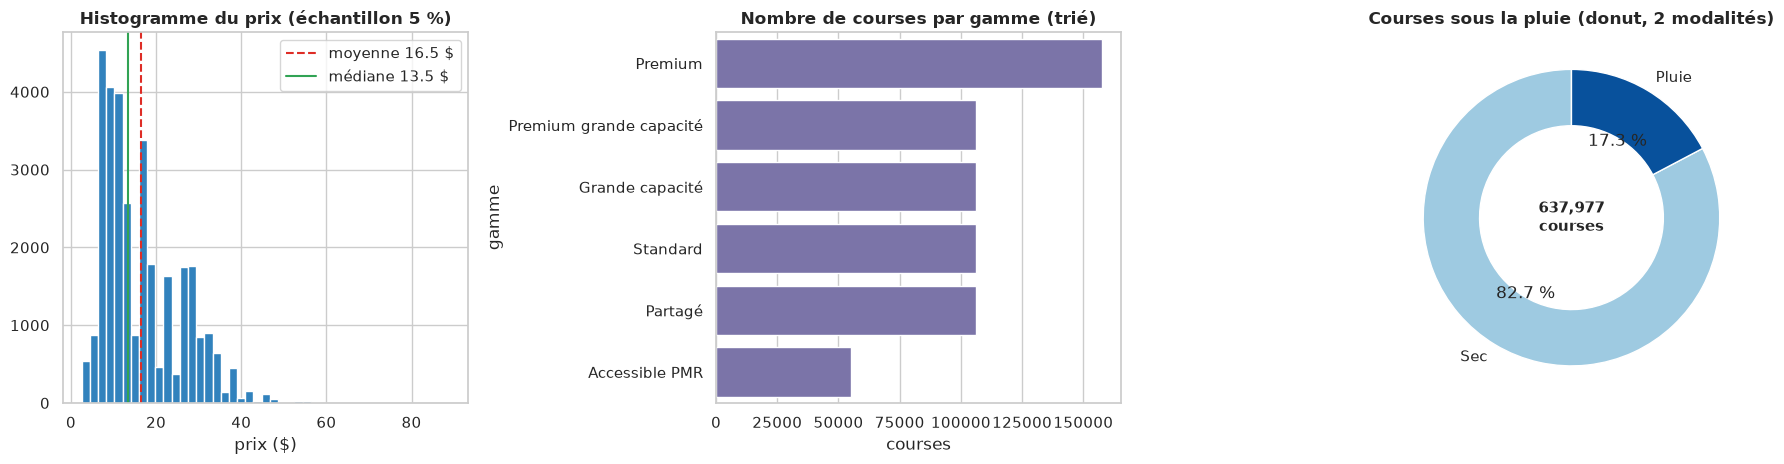

In [6]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
silver_eda = spark.read.format("delta").load(SILVER_MAIN_PATH).cache()

# 1. Paramétrique vs robuste (calculé sur le cluster)
lignes = []
for c in ["price", "distance", "prix_par_mile", "temp_c"]:
    st = silver_eda.select(
        F.mean(c).alias("m"), F.stddev(c).alias("s"),
        F.percentile_approx(c, 0.25).alias("q1"), F.percentile_approx(c, 0.5).alias("med"), F.percentile_approx(c, 0.75).alias("q3"),
    ).first()
    lignes.append({"variable": c, "moyenne": round(st["m"], 2), "mediane": round(st["med"], 2),
                   "ecart_moy_med": round(st["m"] - st["med"], 2), "ecart_type": round(st["s"], 2), "IQR": round(st["q3"] - st["q1"], 2)})
print("=== Tendance centrale & dispersion : paramétrique vs robuste ===")
print(pd.DataFrame(lignes).to_string(index=False))
mode_gamme = silver_eda.groupBy("gamme").count().orderBy(F.desc("count")).first()
print(f"\nMode (gamme la plus fréquente) : {mode_gamme['gamme']} ({mode_gamme['count']:,} courses)")

# 2. Tri croisé pluie x majoration (Lyft)
ct = (silver_eda.filter(F.col("cab_type") == "Lyft").groupBy("is_pluie")
      .agg(F.count("*").alias("courses"), F.round(100 * F.avg("is_surge"), 2).alias("pct_majorees")).orderBy("is_pluie").toPandas())
ct["is_pluie"] = ct["is_pluie"].map({0: "Sec", 1: "Pluie"})
print("\n=== Tri croisé (Lyft) : % de courses majorées selon la pluie ===")
print(ct.to_string(index=False))

# 3. Graphiques 1D
prix_pd = silver_eda.select("price").sample(fraction=0.05, seed=42).toPandas()
par_gamme = (silver_eda.groupBy("gamme").agg(F.count("*").alias("courses"), F.percentile_approx("price", 0.5).alias("prix_median"))
             .orderBy(F.desc("courses")).toPandas())
pluie = silver_eda.groupBy("is_pluie").count().orderBy("is_pluie").toPandas()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].hist(prix_pd["price"], bins=45, color="#3182bd", edgecolor="white")
ax[0].axvline(prix_pd["price"].mean(), color="#de2d26", ls="--", label=f"moyenne {prix_pd['price'].mean():.1f} $")
ax[0].axvline(prix_pd["price"].median(), color="#31a354", ls="-", label=f"médiane {prix_pd['price'].median():.1f} $")
ax[0].set_title("Histogramme du prix (échantillon 5 %)", fontweight="bold"); ax[0].set_xlabel("prix ($)"); ax[0].legend()
sns.barplot(data=par_gamme, y="gamme", x="courses", ax=ax[1], color="#756bb1")
ax[1].set_title("Nombre de courses par gamme (trié)", fontweight="bold")
ax[2].pie(pluie["count"], labels=["Sec", "Pluie"], colors=["#9ecae1", "#08519c"], autopct="%1.1f %%",
          startangle=90, wedgeprops={"width": 0.38})
ax[2].text(0, 0, f"{pluie['count'].sum():,}\ncourses", ha="center", va="center", fontsize=11, fontweight="bold")
ax[2].set_title("Courses sous la pluie (donut, 2 modalités)", fontweight="bold")
plt.tight_layout(); plt.show()

**Lecture 4.1**
- **Prix** : moyenne 16,55 $ > médiane 13,50 $ (+3,05 $), distribution **asymétrique à droite** (histogramme) : la médiane et l'IQR décrivent mieux la course « typique ».
- **Prix au mile** : encore plus asymétrique (moyenne 9,69 $ contre médiane 7,49 $, écart-type 13,71 $). Les **très courts trajets** (0,02 mile) font exploser le ratio : il faudra raisonner en médiane.
- **Distance** : quasi symétrique (moyenne ≈ médiane ≈ 2,2 miles).
- **Mode** : la gamme **Premium** (157 565 courses), car elle regroupe 3 offres (Lux, Lux Black, Black). Le volume par offre est, lui, presque identique : les données viennent de requêtes régulières sur toutes les offres, pas de vraies réservations.
- **Tri croisé** : chez Lyft, **6,69 % des courses sont majorées sous la pluie contre 6,85 % par temps sec**. Contrairement à l'intuition, la pluie n'augmente pas la majoration (à confirmer par un test au Jour 4).
- **17,3 % des courses** ont eu lieu sous la pluie (donut).

### 4.2 Split-Apply-Combine, discrétisation (`cut` vs `qcut`) & visualisations 2D
1. **Agrégation distribuée `.groupBy().agg()`** par heure de Boston et par compagnie, tracée en **courbe** (axe horaire ordonné).
2. **Discrétisation** : `pd.cut` sur la distance (seuils métier fixes) vs `pd.qcut` sur le prix (4 quartiles d'effectifs égaux).
3. **Boxplot** du prix par gamme (médiane, boîte IQR, moustaches à 1,5 × IQR).

=== pd.cut (seuils métier fixes) : effectifs inégaux ===
tranche_distance_cut
< 1 mile      4150
1-2 miles    10956
2-3 miles     9710
> 3 miles     7257

=== pd.qcut (quartiles) : effectifs ~égaux, bornes de prix inégales ===
                    count   min   max
quartile_prix_qcut                   
Q1 (moins cher)      8424   2.5   9.0
Q2                   7825   9.5  13.5
Q3                   8235  14.0  22.5
Q4 (plus cher)       7589  23.0  89.0


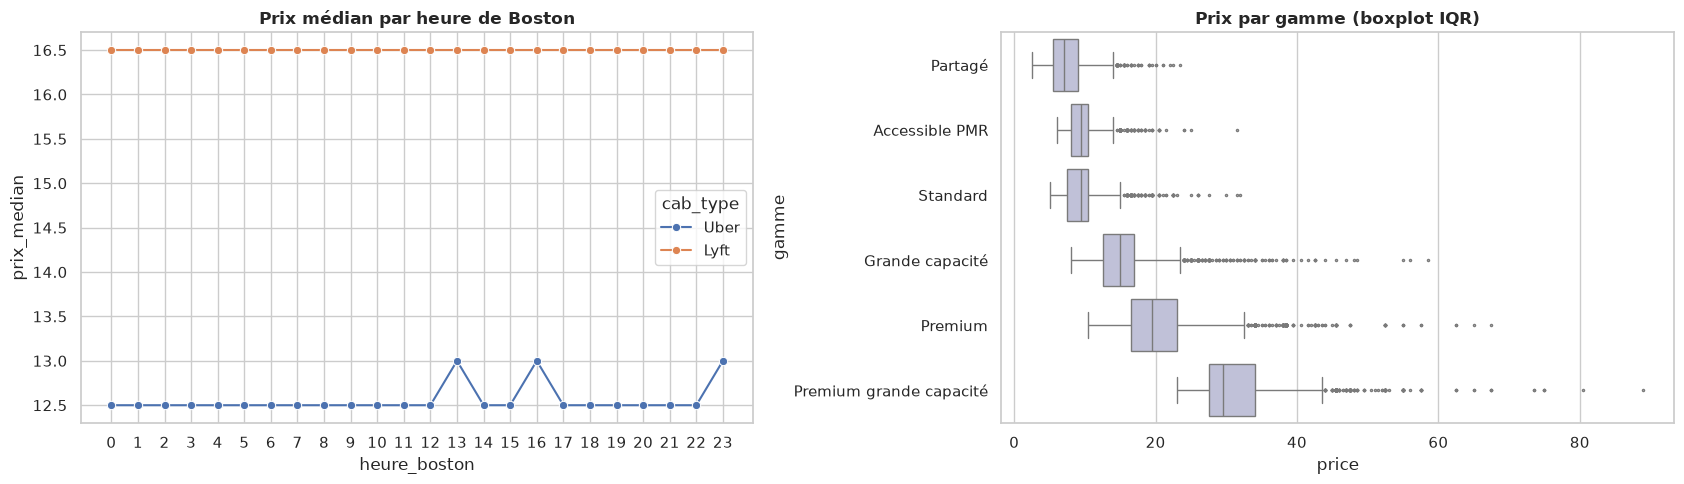

cab_type     Lyft     Uber
count        24.0     24.0
mean      12809.0  13774.0
std         983.0   1019.0
min       10700.0  11637.0
25%       12402.0  13176.0
50%       13098.0  13810.0
75%       13396.0  14559.0
max       14657.0  15351.0


In [7]:
# 1. Prix médian et volume par heure de Boston et par compagnie (tri chronologique)
horaire_pd = (silver_eda.groupBy("heure_boston", "cab_type")
              .agg(F.count("*").alias("courses"), F.percentile_approx("price", 0.5).alias("prix_median"),
                   F.round(100 * F.avg("is_surge"), 2).alias("pct_majorees"))
              .orderBy("heure_boston").toPandas())

# 2. Discrétisation sur un échantillon
ech = silver_eda.select("distance", "price", "gamme").sample(fraction=0.05, seed=42).toPandas()
ech["tranche_distance_cut"] = pd.cut(ech["distance"], bins=[0, 1, 2, 3, 8],
                                     labels=["< 1 mile", "1-2 miles", "2-3 miles", "> 3 miles"], include_lowest=True)
ech["quartile_prix_qcut"] = pd.qcut(ech["price"], q=4, labels=["Q1 (moins cher)", "Q2", "Q3", "Q4 (plus cher)"], duplicates="drop")
print("=== pd.cut (seuils métier fixes) : effectifs inégaux ===")
print(ech["tranche_distance_cut"].value_counts().sort_index().to_string())
print("\n=== pd.qcut (quartiles) : effectifs ~égaux, bornes de prix inégales ===")
print(ech.groupby("quartile_prix_qcut", observed=True)["price"].agg(["count", "min", "max"]).to_string())

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
sns.lineplot(data=horaire_pd, x="heure_boston", y="prix_median", hue="cab_type", marker="o", ax=ax[0])
ax[0].set_xticks(range(0, 24)); ax[0].set_title("Prix médian par heure de Boston", fontweight="bold")
ordre = ech.groupby("gamme")["price"].median().sort_values().index
sns.boxplot(data=ech, x="price", y="gamme", order=ordre, ax=ax[1], color="#bcbddc", fliersize=1.5)
ax[1].set_title("Prix par gamme (boxplot IQR)", fontweight="bold")
plt.tight_layout(); plt.show()
print(horaire_pd.pivot(index="heure_boston", columns="cab_type", values="courses").describe().round(0).to_string())

**Lecture 4.2**
- **Par heure** : le prix médian est **quasiment plat** sur 24 h (≈ 16,5 $ chez Lyft, ≈ 12,5 $ chez Uber) et les volumes horaires sont réguliers (≈ 11 000 à 15 000 courses par heure et par compagnie). L'heure seule influence très peu le prix ; l'écart Uber / Lyft vient surtout du **mix d'offres** (les gammes premium Lyft sont plus chères).
- **`pd.cut` vs `pd.qcut`** : les seuils métier de distance donnent des groupes **d'effectifs inégaux** (la tranche 1-2 miles domine), tandis que les quartiles de prix donnent des groupes **d'effectifs ~égaux** aux bornes inégales (Q4 couvre de 23 $ à 89 $).
- **Boxplot** : la **gamme** est le facteur le plus discriminant du prix. Les boîtes IQR ne se chevauchent presque pas entre Standard, Grande capacité, Premium et Premium grande capacité ; les points au-delà des moustaches sont surtout des courses premium longues.

### 4.3 Analyse multivariée : Pearson vs Spearman & ACP (PCA) des trajets
1. **Pearson ($r$)** ne voit que les liens *linéaires* et se laisse tirer par les extrêmes ; **Spearman ($\rho$)** travaille sur les **rangs** (liens monotones, robuste). *Corrélation ≠ causalité.*
2. **ACP** : chaque **trajet** (quartier de départ → quartier d'arrivée) est résumé par 6 indicateurs, **standardisés** (`StandardScaler`) puis projetés sur le plan factoriel `(PC1, PC2)`.

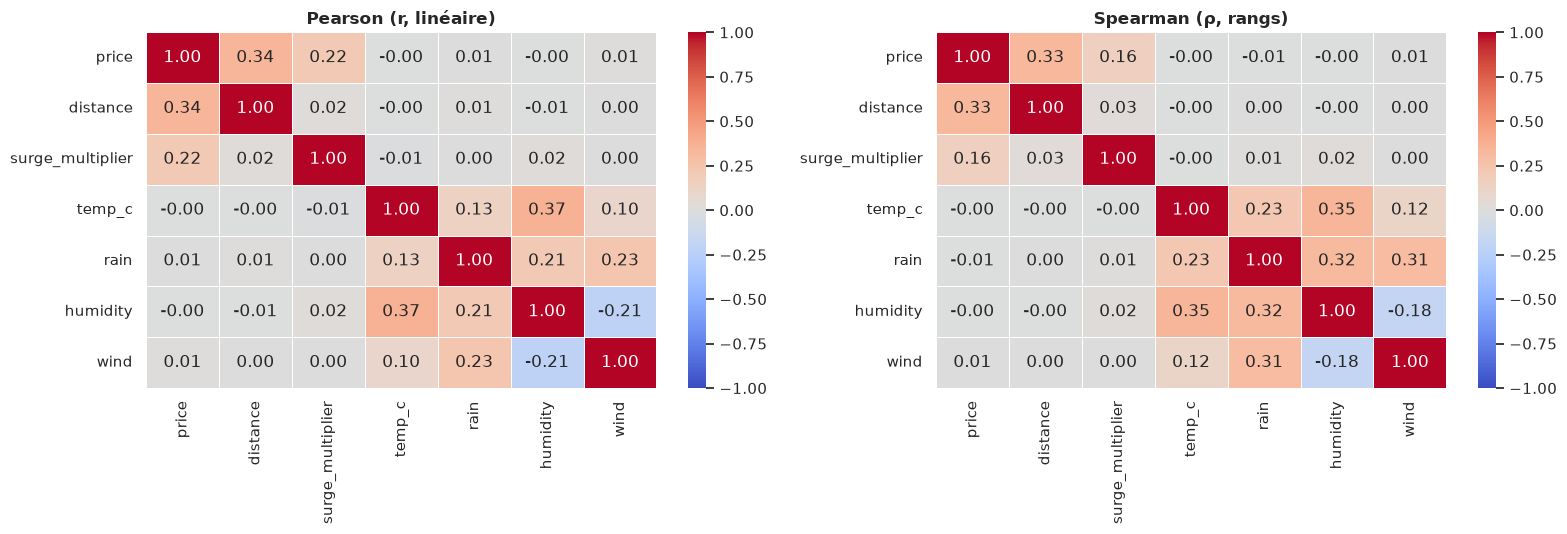

72 trajets | variance expliquée : PC1 = 47.5%, PC2 = 20.3%
                   PC1   PC2
courses           0.04  0.70
prix_median       0.57  0.10
distance_mediane  0.57  0.09
prix_mile_median -0.53  0.17
taux_majoration   0.26 -0.07
gamme_moyenne    -0.04  0.68


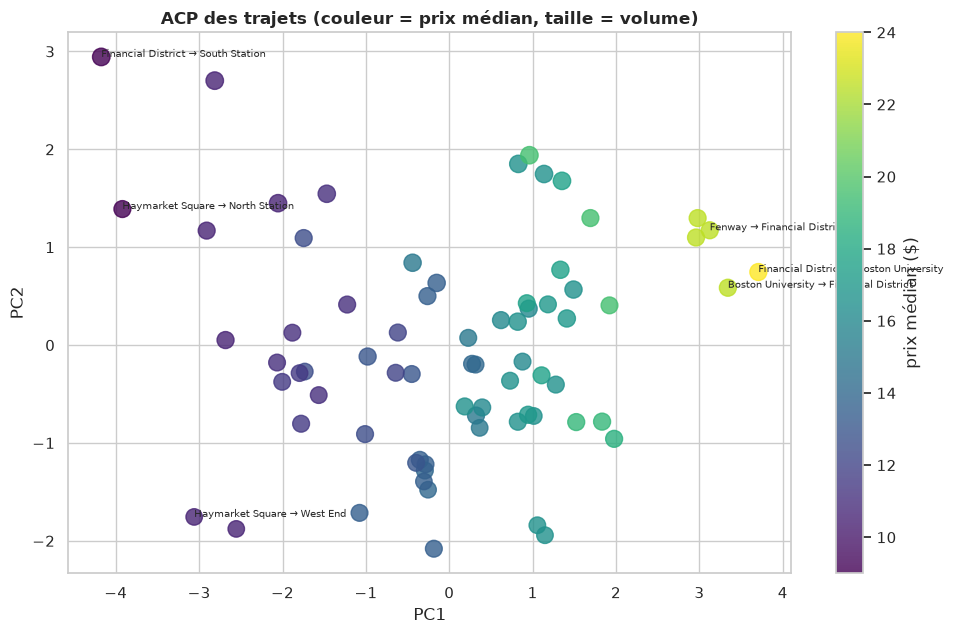

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Pearson vs Spearman (échantillon 3 %)
cols = ["price", "distance", "surge_multiplier", "temp_c", "rain", "humidity", "wind"]
corr_pd = silver_eda.select(cols).sample(fraction=0.03, seed=42).toPandas()
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for a, meth, titre in [(ax[0], "pearson", "Pearson (r, linéaire)"), (ax[1], "spearman", "Spearman (ρ, rangs)")]:
    sns.heatmap(corr_pd.corr(method=meth), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=a, linewidths=0.5)
    a.set_title(titre, fontweight="bold")
plt.tight_layout(); plt.show()

# 2. ACP sur les profils de trajets (agrégés sur le cluster)
trajets_pd = (silver_eda.groupBy("trajet").agg(
    F.count("*").alias("courses"), F.percentile_approx("price", 0.5).alias("prix_median"),
    F.percentile_approx("distance", 0.5).alias("distance_mediane"), F.percentile_approx("prix_par_mile", 0.5).alias("prix_mile_median"),
    F.avg("is_surge").alias("taux_majoration"), F.avg("niveau_gamme").alias("gamme_moyenne"),
).toPandas())
feats = ["courses", "prix_median", "distance_mediane", "prix_mile_median", "taux_majoration", "gamme_moyenne"]
X = StandardScaler().fit_transform(trajets_pd[feats])
pca = PCA(n_components=2, random_state=42).fit(X)
coords = pca.transform(X)
print(f"{len(trajets_pd)} trajets | variance expliquée : PC1 = {pca.explained_variance_ratio_[0]:.1%}, PC2 = {pca.explained_variance_ratio_[1]:.1%}")
print(pd.DataFrame(pca.components_.T, index=feats, columns=["PC1", "PC2"]).round(2).to_string())

fig, axp = plt.subplots(figsize=(10, 6.5))
sc = axp.scatter(coords[:, 0], coords[:, 1], c=trajets_pd["prix_median"], s=trajets_pd["courses"] / 60, cmap="viridis", alpha=0.8)
for i in np.argsort(-np.abs(coords[:, 0]))[:6]:
    axp.annotate(trajets_pd["trajet"][i], coords[i], fontsize=7)
axp.set_xlabel("PC1"); axp.set_ylabel("PC2"); axp.set_title("ACP des trajets (couleur = prix médian, taille = volume)", fontweight="bold")
plt.colorbar(sc, label="prix médian ($)"); plt.tight_layout(); plt.show()

**Lecture 4.3**
- **Corrélations** : parmi les variables numériques, le prix est lié à la **distance** (r = 0,34 ; ρ = 0,33) et à la **majoration** (r = 0,22 ; ρ = 0,16). Ces liens ne sont que **modérés**, car le facteur dominant est la **gamme**, qualitative et absente de la heatmap (voir le boxplot). Les variables météo (température, pluie, humidité, vent) ont des corrélations **nulles avec le prix** (|r| ≤ 0,01).
- **Pearson vs Spearman** : les écarts portent surtout sur la **pluie**, une variable à 83 % de zéros et très asymétrique. Pluie ↔ vent passe de r = 0,23 à ρ = 0,31, et pluie ↔ température de 0,13 à 0,23 : Spearman, qui travaille sur les rangs, capte mieux ces liens monotones non linéaires. *Corrélation ≠ causalité :* la météo et le prix ne sont pas liés ici, car la majoration dépend de la demande, pas de la pluie elle-même.
- **ACP des 72 trajets** : **PC1 (47,5 %)** oppose les trajets **longs et chers** (prix médian et distance : +0,57) aux trajets **courts mais chers au mile** (prix au mile : −0,53). **PC2 (20,3 %)** traduit le **volume** et le **mix de gammes** du trajet. Le K-Means du Jour 4 s'appuiera sur ces mêmes indicateurs.